# Univariate regression
This notebook shows three ways of coding a sheaf to solve a univariate linear regression problem.  The final way uses the constraints feature of `Cell`.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import pysheaf as ps

%load_ext autoreload
%autoreload 2

### Problem
Fit the following data.  Solution:

**slope = 1**

**intercept = 0**

In [2]:
# data_dict = {'x': [0,0.5,0.5,1], 'y': [0,0,1,1]}
data_dict = {'x': [0,1,1], 'y': [0,0.5,1.5]}
# data_dict = {'x': [0,1], 'y': [0,1]}
data = pd.DataFrame(data_dict)
data

,x,y
0,0,0.0
1,1,0.5
2,1,1.5


Text(0, 0.5, 'y')

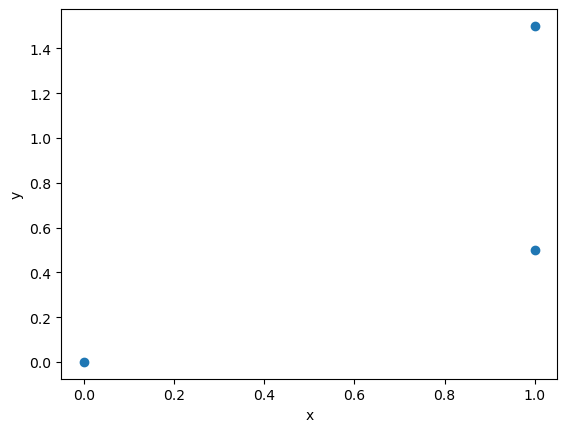

In [3]:
plt.scatter(data.x, data.y)
plt.xlabel('x')
plt.ylabel('y')

### Sheaf #1
This sheaf gives the correct results, but the x-values are stored in the restriction map.  This seems inconvenient for reusing the x-values in other calculations since they may need to be duplicated in other parts of the sheaf.

In [4]:
shf=ps.Sheaf()
shf.mNumpyNormType = 2

#-> This cell only holds the intercept and slope.
shf.AddCell('intercept_slope',ps.Cell('R^2', dataDimension=2))
shf.GetCell('intercept_slope').SetDataAssignment(ps.Assignment('R^2', np.zeros(2)))
shf.GetCell('intercept_slope').mOptimizationCell = True 

#-> This holds the y-values:  [y0, y1, y2, y3, ...]
shf.AddCell('y',ps.Cell('R^N', dataDimension=len(data)))
shf.GetCell('y').SetDataAssignment(ps.Assignment('R^N', data.y.to_numpy()))

The restriction map calculates y = intercept + slope*x

In [5]:
x_np_array = data.x.to_numpy()
shf.AddCoface('intercept_slope','y',ps.Coface('R^2','R^N',lambda x : x[0] + x[1]*x_np_array))

Visualize

/tmp/ipykernel_263957/1786920495.py:3: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(shf,pos)


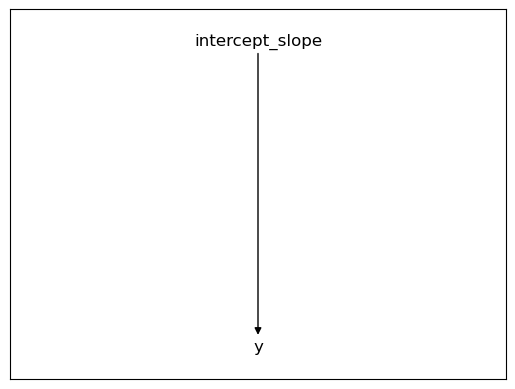

In [6]:
pos=nx.nx_agraph.graphviz_layout(shf, prog="dot")
nx.draw_networkx_labels(shf,pos)
nx.draw_networkx_edges(shf,pos)

Check consistency before optimization.

In [7]:
for c in shf.GetCellIndexList():
    shf.MaximallyExtendCell(c)

consistency_radius = shf.ComputeConsistencyRadius()
print("Consistency radius before optimization: {}".format(consistency_radius))

Consistency radius before optimization: 1.5811388300841898


Optimize


In [8]:
shf.FuseAssignment()
print("Consistency radius after optimization: {}".format(shf.ComputeConsistencyRadius()))

Consistency radius after optimization: 0.7071068337468049


Print path coefficients


In [9]:
intercept = shf.GetCell('intercept_slope').mDataAssignment.mValue[0]
print(f"intercept: {intercept}")
slope = shf.GetCell('intercept_slope').mDataAssignment.mValue[1]
print(f"slope: {slope}")

intercept: -0.00022210391584721097
slope: 1.0003339101819007


### Sheaf #2 
This sheaf takes the x-values out of the restriction map and puts them in their own cell.  To make the sheaf return the correct intercept and slope, we have to weight the consistency on that cell by an arbitrarily large number (10.0).

In [10]:
shf=ps.Sheaf()
shf.mNumpyNormType = 2

#-> This holds the following data:  [intercept, slope, x0, x1, x2, x3, ...]
shf.AddCell('intercept_slope_x',ps.Cell('R^(2+N)', dataDimension=2+len(data)))
shf.GetCell('intercept_slope_x').SetDataAssignment(ps.Assignment('R^(2+N)', np.zeros(2+len(data))))
shf.GetCell('intercept_slope_x').mOptimizationCell = True 

#-> This holds the following data:  [x0, x1, x2, x3, ...]
shf.AddCell('x',ps.Cell('R^N', dataDimension=len(data)))
#-> I added the ability to weight a cell's consistency in the code, 
#   SO THIS CELL PROBABLY WON'T WORK FOR YOU. 
#   Here, I'm applying an arbitrarily large weight to ensure the x-values don't change a lot during optimization.
shf.GetCell('x').mConsistancyWeight = 10.
shf.GetCell('x').SetDataAssignment(ps.Assignment('R^N', data.x.to_numpy()))

#-> This holds the following data:  [y0, y1, y2, y3, ...]
shf.AddCell('y',ps.Cell('R^N', dataDimension=len(data)))
shf.GetCell('y').SetDataAssignment(ps.Assignment('R^N', data.y.to_numpy()))

In [11]:
shf.AddCoface('intercept_slope_x','y',ps.Coface('R^(2+N)','R^N',lambda x : x[0] + x[1]*x[2:]))
shf.AddCoface('intercept_slope_x','x',ps.Coface('R^(2+N)','R^N',lambda x : x[2:]))

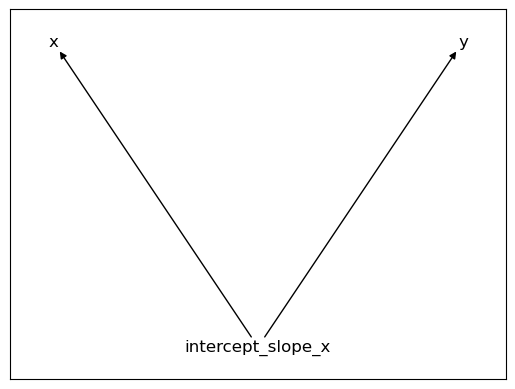

In [12]:
pos=nx.layout.spectral_layout(shf)
nx.draw_networkx_labels(shf,pos)
nx.draw_networkx_edges(shf,pos)

Check consistency before optimization.

In [13]:
for c in shf.GetCellIndexList():
    shf.MaximallyExtendCell(c)

consistency_radius = shf.ComputeConsistencyRadius()
print("Consistency radius before optimization: {}".format(consistency_radius))

Consistency radius before optimization: 14.230249470757707


Optimize


In [14]:
shf.FuseAssignment()
print("Consistency radius after optimization: {}".format(shf.ComputeConsistencyRadius()))

Consistency radius after optimization: 0.7035717457793196


Print results

In [15]:
intercept = shf.GetCell('intercept_slope_x').mDataAssignment.mValue[0]
print(f"intercept: {intercept}")
slope = shf.GetCell('intercept_slope_x').mDataAssignment.mValue[1]
print(f"slope: {slope}")

intercept: -0.004622783221409902
slope: 1.007101192784123


### Solution using Lagrange multipliers

First approach:  optimize x-values separately.  Here, there are as many Lagrange multipliers as there are x-observations.

In [16]:
from scipy.optimize import minimize, root
from scipy.optimize._numdiff import approx_derivative

def f(x, data=data):
    x_obs = data.x.to_numpy()
    y_obs = data.y.to_numpy()
    x_norm = np.linalg.norm(x[2:] - x_obs,2)
    y_norm = np.linalg.norm(x[0]+x[1]*x[2:] - y_obs, 2)
    return np.linalg.norm([x_norm, y_norm], 2)

def constraints(x, data=data):
    x_obs = data.x.to_numpy()
    return x[2:len(x_obs)+2] - x_obs

def f_grad(x):
    return approx_derivative(f, x)

def g_jac(x):
    return approx_derivative(constraints, x)

def H(z, f_grad, g, g_jac):
    g_evaluated = g(z)
    x, λ   = np.split(z, (-g_evaluated.size, ))
    eq1 = f_grad(x) + g_jac(x).T @ λ
    eq2 = g_evaluated
    return np.array([*eq1, *eq2])

res = root(lambda z: H(z, f_grad, constraints, g_jac), x0=np.ones(2*len(data)+2))
print(f"intercept = {res.x[0]}")
print(f"slope = {res.x[1]}")
x_obs = data.x.to_numpy()
print(f"observed x-values = {x_obs}")
print(f"solved x-values = {res.x[2:len(x_obs)+2]}")
print(f"multipliers = {res.x[len(x_obs)+2:]}")


intercept = 4.926124731755324e-11
slope = 1.000000000002941
observed x-values = [0 1 1]
solved x-values = [-1.14679214e-19  1.00000000e+00  1.00000000e+00]
multipliers = [-6.04538295e-11 -7.07106781e-01  7.07106781e-01]


Second approach:  optimize the norm of the difference between observed and optimzed x-avlues.  Here, there is 1 Lagrange multiplier.

In [17]:
def f(x, data=data):
    x_obs = data.x.to_numpy()
    y_obs = data.y.to_numpy()
    x_norm = np.linalg.norm(x[2:] - x_obs,2)
    y_norm = np.linalg.norm(x[0]+x[1]*x[2:] - y_obs, 2)
    return np.linalg.norm([x_norm, y_norm], 2)

def constraints(x, data=data):
    x_obs = data.x.to_numpy()
    return np.linalg.norm(x[2:len(x_obs)+2] - x_obs, 2)

def f_grad(x):
    return approx_derivative(f, x)

def g_jac(x):
    return approx_derivative(constraints, x)

def H(z, f_grad, g, g_jac):
    x = z[:-1]
    λ = z[-1] 
    # g_evaluated = g(x)
    eq1 = f_grad(x) + g_jac(x).T * λ
    eq2 = g(x)
    return np.array([*eq1, eq2])

res = root(lambda z: H(z, f_grad, constraints, g_jac), x0=np.ones(len(data)+3))
print(f"intercept = {res.x[0]}")
print(f"slope = {res.x[1]}")
x_obs = data.x.to_numpy()
print(f"observed x-values = {x_obs}")
print(f"solved x-values = {res.x[2:len(x_obs)+2]}")
print(f"multipliers = {res.x[len(x_obs)+2:]}")


intercept = 9.05020931759008e-06
slope = 0.9999864810740269
observed x-values = [0 1 1]
solved x-values = [1.69888329e-10 1.00000900e+00 9.99991004e-01]
multipliers = [-1.06111405]


Third approach:  using SciPy

In [18]:
def f(x, data=data):
    x_obs = data.x.to_numpy()
    y_obs = data.y.to_numpy()
    x_norm = np.linalg.norm(x[2:] - x_obs,2)
    y_norm = np.linalg.norm(x[0]+x[1]*x[2:] - y_obs, 2)
    return np.linalg.norm([x_norm, y_norm], 2)

def constraints(x, data=data):
    x_obs = data.x.to_numpy()
    # return np.linalg.norm(x[2:len(x_obs)+2] - x_obs, 2)
    return None 

x0=np.ones(len(data)+2)
# cons = ({'type': 'eq', 'fun': constraints})
cons = None 
result = minimize(f, x0, method='SLSQP', constraints=cons)

print(result)

 message: Optimization terminated successfully
 success: True
  status: 0
     fun: 0.4524011328320279
       x: [-2.951e-01  1.443e+00  1.383e-01  6.971e-01  1.165e+00]
     nit: 11
     jac: [ 1.669e-03  8.812e-04  1.082e-03  2.243e-03 -9.475e-05]
    nfev: 71
    njev: 11


### Sheaf #3 
This sheaf has the same topology as Sheaf #2, but uses contraints.

In [19]:
shf=ps.Sheaf()
shf.mNumpyNormType = 2

#-> This holds the following data:  [intercept, slope, x0, x1, x2, x3, ...]
shf.AddCell('intercept_slope_x',ps.Cell('R^(2+N)', dataDimension=2+len(data)))
shf.GetCell('intercept_slope_x').SetDataAssignment(ps.Assignment('R^(2+N)', np.zeros(2+len(data))))
shf.GetCell('intercept_slope_x').mOptimizationCell = True 

#-> This holds the following data:  [x0, x1, x2, x3, ...]
shf.AddCell('x',ps.Cell('R^N', dataDimension=len(data)))
shf.GetCell('x').SetDataAssignment(ps.Assignment('R^N', data.x.to_numpy()))
shf.GetCell('x').mConstraintType = ps.CellConstraintType.EQUALITY

#-> This holds the following data:  [y0, y1, y2, y3, ...]
shf.AddCell('y',ps.Cell('R^N', dataDimension=len(data)))
shf.GetCell('y').SetDataAssignment(ps.Assignment('R^N', data.y.to_numpy()))

In [20]:
shf.AddCoface('intercept_slope_x','y',ps.Coface('R^(2+N)','R^N',lambda x : x[0] + x[1]*x[2:]))
shf.AddCoface('intercept_slope_x','x',ps.Coface('R^(2+N)','R^N',lambda x : x[2:]))

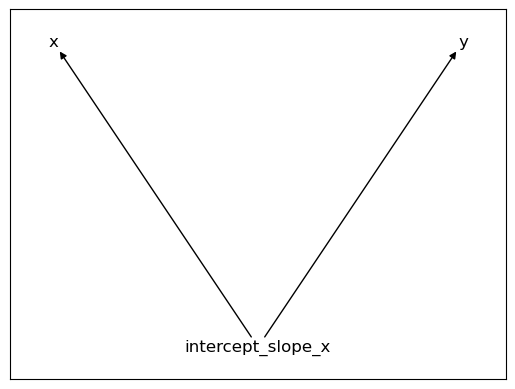

In [21]:
pos=nx.layout.spectral_layout(shf)
nx.draw_networkx_labels(shf,pos)
nx.draw_networkx_edges(shf,pos)

Check consistency before optimization.

In [22]:
for c in shf.GetCellIndexList():
    shf.MaximallyExtendCell(c)

consistency_radius = shf.ComputeConsistencyRadius()
print("Consistency radius pre-optimization, all cells: {}".format(consistency_radius))

constraint_consistency_radius = shf.ComputeConsistencyRadius(cellTypes=ps.CellType.CONSTRAINT) 
print("Consistency radius pre-optimization, constraint cells: {}".format(constraint_consistency_radius))

nonconstraint_consistency_radius = shf.ComputeConsistencyRadius(cellTypes=ps.CellType.NON_CONSTRAINT) 
print("Consistency radius pre-optimization, non-constraint cells: {}".format(nonconstraint_consistency_radius))

Consistency radius pre-optimization, all cells: 2.121320343559643
Consistency radius pre-optimization, constraint cells: 1.4142135623730951
Consistency radius pre-optimization, non-constraint cells: 1.5811388300841898


Optimize


In [23]:
shf.FuseAssignment()
print("Consistency radius after optimization: {}".format(shf.ComputeConsistencyRadius()))

Consistency radius after optimization: 0.7070971504588948


Print results

In [24]:
intercept = shf.GetCell('intercept_slope_x').mDataAssignment.mValue[0]
print(f"intercept: {intercept}")
slope = shf.GetCell('intercept_slope_x').mDataAssignment.mValue[1]
print(f"slope: {slope}")

intercept: -8.198503756991328e-06
slope: 1.0000118653892467
